# Throughput & QoS Satisfaction Analysis

## Stadium RF Simulation — Realistic RU Carrier Reuse



This notebook evaluates per-UE throughput with a more realistic RU frequency plan.

Instead of assigning a dedicated 100 MHz carrier to every RU, the deployment now uses

a reuse-3 mid-band layout with three contiguous 100 MHz carriers shared across 56 O-RUs.



The load model also assumes that not all attached users request PRB resources at the same time.

An explicit activity factor is used to model simultaneous demand and capture statistical multiplexing.



> **Note**

> The current activity factor is set to 0.245, derived as $0.70 \times 0.35$.

> This follows the large-event dimensioning logic discussed for FIFA World Cup Qatar 2022:

> about 70% of attached users may have active sessions at peak, while only 35% of those

> active users are scheduled for downlink PRBs in a given TTI. In this notebook, that product

> is used as the approximate fraction of attached UEs simultaneously competing for PRBs.



**Model:** per-cell fair share with co-channel interference from same-frequency RUs:



$$T_{\mathrm{UE}} = n_t \times \eta \times \frac{\mathrm{BW}_{\mathrm{cell}}}{N_{\mathrm{active\ UEs\ on\ cell}}} \times \log_2(1 + \mathrm{SINR})$$



| Parameter | Value | Source |

|---|---|---|

| $n_t$ (MIMO layers) | 4 | Paper Table I |

| $\eta$ (NR efficiency) | 0.70 | 3GPP practical overhead |

| Carrier plan | Reuse-3 over 3400/3500/3600 MHz | `frequency_plan.py` |

| Unique licensed spectrum | 300 MHz | 3 carriers × 100 MHz |

| SINR | Includes co-channel interference from same-frequency RUs | `analyze_throughput.py` |

| Activity factor | 0.245 (= 0.70 × 0.35) | Large-event attached-to-scheduled DL assumption |

| Demand range | 0.5–25 Mbps | §Metrics Collection |

## 1. Setup & Imports

In [12]:
import importlib

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from pathlib import Path

import throughput_model
import analyze_throughput

throughput_model = importlib.reload(throughput_model)
analyze_throughput = importlib.reload(analyze_throughput)


# Project modules

from throughput_model import (

    DEFAULT_BANDWIDTH_MHZ, DEFAULT_EFFICIENCY, N_MIMO_LAYERS,

    DEMAND_MIN_MBPS, DEMAND_MAX_MBPS, sinr_to_throughput, assign_demands

 )

from analyze_throughput import (

    run_scenario, run_all_scenarios, setup_plot_style,

    run_all_scenarios_percell, plot_handover_interference,

    plot_throughput_cdf, plot_achieved_vs_demanded,

    plot_satisfaction_vs_load, plot_per_tier_throughput,

    plot_handover_continuity, build_handover_comparison_table, print_summary_table,

    NUM_RUS, CHANNEL_BW, CARRIER_POOL_MHZ, REUSE_FACTOR, TOTAL_UNIQUE_BW_MHZ

 )


# Enable inline plots

%matplotlib inline

setup_plot_style(font_size=14)


# Large-event concurrency assumption: 70% active-session users × 35% DL scheduling

ACTIVE_USER_FACTOR = 0.245


# Trace inputs for observed peak-load calibration

UE_TRACE_PATH = Path('input_full.csv')
POWER_LOG_PATH = Path('logs/26.08.2025/cell_power_changes_20250826_212044.csv')


# Output directory

output_dir = Path('plots/throughput')

output_dir.mkdir(parents=True, exist_ok=True)


ue_trace = pd.read_csv(UE_TRACE_PATH)
power_trace = pd.read_csv(POWER_LOG_PATH)

pci_columns = [column for column in power_trace.columns if column.startswith('pci_')]
power_trace['active_cells'] = power_trace[pci_columns].fillna(0).gt(0).sum(axis=1)

peak_trace_row = ue_trace.loc[ue_trace['Connected UEs'].idxmax()].copy()
peak_connected_ues = int(round(float(peak_trace_row['Connected UEs'])))
peak_time_h = float(peak_trace_row['Time(h)'])

nearest_power_idx = (power_trace['Time(h)'] - peak_time_h).abs().idxmin()
peak_power_row = power_trace.loc[nearest_power_idx].copy()
observed_active_cells = int(peak_power_row['active_cells'])
peak_power_time_h = float(peak_power_row['Time(h)'])
connected_ues_per_active_cell = (
    peak_connected_ues / observed_active_cells if observed_active_cells else np.nan
)

# Active-cell occupancy is a coarse proxy, not direct PRB utilization.
ACTIVE_CELL_OCCUPANCY_RATIO = observed_active_cells / NUM_RUS
ACTIVE_CELL_OCCUPANCY_PCT = ACTIVE_CELL_OCCUPANCY_RATIO * 100.0
EFFECTIVE_BW_PER_RU_MHZ = DEFAULT_BANDWIDTH_MHZ * ACTIVE_CELL_OCCUPANCY_RATIO


# Display formatting for compact comparison tables

pd.options.display.float_format = '{:.2f}'.format

print(f"Model parameters:")

print(f"  MIMO layers (n_t):          {N_MIMO_LAYERS}")

print(f"  NR efficiency (eta):        {DEFAULT_EFFICIENCY}")

print(f"  BW per RU (nominal):        {DEFAULT_BANDWIDTH_MHZ} MHz")

print(f"  BW per RU (effective):      {EFFECTIVE_BW_PER_RU_MHZ:.1f} MHz")

print(f"  Active-cell occupancy:      {ACTIVE_CELL_OCCUPANCY_PCT:.1f}% ({observed_active_cells}/{NUM_RUS})")

print(f"  Carrier pool:               {list(CARRIER_POOL_MHZ)} MHz")

print(f"  Frequency reuse factor:     {REUSE_FACTOR}")

print(f"  Unique licensed spectrum:   {TOTAL_UNIQUE_BW_MHZ} MHz")

print(f"  Active-user factor:         {ACTIVE_USER_FACTOR:.3f}")

print(f"  Number of RUs:              {NUM_RUS}")

print(f"  Demand range:               [{DEMAND_MIN_MBPS}, {DEMAND_MAX_MBPS}] Mbps")

print(f"  Observed peak load:         {peak_connected_ues} UEs at {peak_time_h:.3f} h")

print(f"  Peak power snapshot:        {peak_power_time_h:.3f} h")


Model parameters:
  MIMO layers (n_t):          4
  NR efficiency (eta):        0.7
  BW per RU (nominal):        100 MHz
  BW per RU (effective):      67.9 MHz
  Active-cell occupancy:      67.9% (38/56)
  Carrier pool:               [3400, 3500, 3600] MHz
  Frequency reuse factor:     3
  Unique licensed spectrum:   300 MHz
  Active-user factor:         0.245
  Number of RUs:              56
  Demand range:               [0.5, 25.0] Mbps
  Observed peak load:         9096 UEs at 20.504 h
  Peak power snapshot:        20.644 h


## 2. Run Scenarios

Simulate baseline load levels from 256 to 8192 UEs using the realistic reuse-3 carrier plan,

vectorized same-carrier interference computation, an activity factor so only an estimated

24.5% of attached users competes for PRBs at the same instant, and an active-cell occupancy

proxy derived from the nearest power-log snapshot at the observed peak load.

The 24.5% activity factor comes from $0.70 \times 0.35$, matching the attached-user to

scheduled-user interpretation used in the note above. The occupancy proxy scales the

effective per-RU bandwidth by the active fraction of the 56 configured RUs.

In [13]:
observed_peak_connected_ues = peak_connected_ues

baseline_ue_counts = [256, 512, 1024, 2048, 3072, 4096, 6144, 8192]
ue_counts = sorted(set(baseline_ue_counts + [observed_peak_connected_ues]))

print(f"Observed peak load added to sweep: {observed_peak_connected_ues} connected UEs")
print(f"Active-cell occupancy proxy:       {ACTIVE_CELL_OCCUPANCY_PCT:.1f}%")
print(f"Effective BW per RU in sweep:      {EFFECTIVE_BW_PER_RU_MHZ:.1f} MHz")

results = run_all_scenarios(
    ue_counts,
    seed=42,
    bandwidth_mhz=EFFECTIVE_BW_PER_RU_MHZ,
    activity_factor=ACTIVE_USER_FACTOR,
 )

Observed peak load added to sweep: 9096 connected UEs
Active-cell occupancy proxy:       67.9%
Effective BW per RU in sweep:      67.9 MHz

Running scenario: 256 UEs

--- Summary for 256 UEs (0.01s) ---
  Satisfaction: 100.0% of UEs meet their demand
  Throughput — mean: 175.0 Mbps, median: 151.7 Mbps, min: 31.9 Mbps, max: 357.3 Mbps
  Demand    — mean: 12.7 Mbps, median: 12.5 Mbps
  SINR      — mean: 1.5 dB, min: -4.5 dB, max: 4.9 dB
  UEs/cell  — mean: 5.7, max: 10
  Active UEs/cell — mean: 1.8, max: 5, activity factor: 0.24
  Tier Lower: sat=100.0%, tput_mean=210.9 Mbps, sinr_mean=2.3 dB
  Tier Middle: sat=100.0%, tput_mean=152.0 Mbps, sinr_mean=0.7 dB
  Tier Upper: sat=100.0%, tput_mean=161.6 Mbps, sinr_mean=1.5 dB

Running scenario: 512 UEs

--- Summary for 512 UEs (0.01s) ---
  Satisfaction: 100.0% of UEs meet their demand
  Throughput — mean: 139.0 Mbps, median: 105.0 Mbps, min: 20.3 Mbps, max: 378.2 Mbps
  Demand    — mean: 12.7 Mbps, median: 12.8 Mbps
  SINR      — mean: 1.4 d

## 3. Summary Table & Load Trend

The table and curve below include the observed peak load from `input_full.csv` and use the

same active-cell occupancy proxy to scale effective per-RU bandwidth across the scenario sweep.

In [14]:
print_summary_table(results)
print()
print(f"Observed peak scenario in summary: {max(ue_counts)} UEs")
print(f"Active-cell occupancy proxy:       {ACTIVE_CELL_OCCUPANCY_PCT:.1f}%")
print(f"Effective BW per RU:               {EFFECTIVE_BW_PER_RU_MHZ:.1f} MHz")


THROUGHPUT & QoS SATISFACTION SUMMARY
   UEs |   Sat% |  Tput Mean |  Tput Med |  Tput Min |  SINR Mean |  UEs/Cell
-----------------------------------------------------------------------------
   256 | 100.0% |    175.0 M |   151.7 M |    31.9 M |      1.5 dB |     5.7
   512 | 100.0% |    139.0 M |   105.0 M |    20.3 M |      1.4 dB |    10.3
  1024 |  97.1% |     74.9 M |    55.3 M |     7.2 M |      1.2 dB |    20.2
  2048 |  85.7% |     29.8 M |    25.2 M |     5.7 M |      1.2 dB |    39.2
  3072 |  65.9% |     18.1 M |    16.3 M |     3.1 M |      1.2 dB |    58.2
  4096 |  53.7% |     14.0 M |    12.5 M |     2.7 M |      1.3 dB |    77.2
  6144 |  34.2% |      8.9 M |     8.1 M |     1.9 M |      1.3 dB |   115.7
  8192 |  26.9% |      7.0 M |     6.3 M |     1.4 M |      1.3 dB |   153.8
  9096 |  22.5% |      6.0 M |     5.5 M |     1.3 M |      1.3 dB |   170.6

Per-Tier Breakdown at Peak Load (9096 UEs):
Tier     |   Sat% |  Tput Mean |  SINR Mean |  Count
--------------

### Satisfaction Ratio Across Simulated and Observed Loads

The rightmost point reflects the observed peak connected-UE count from `input_full.csv`.

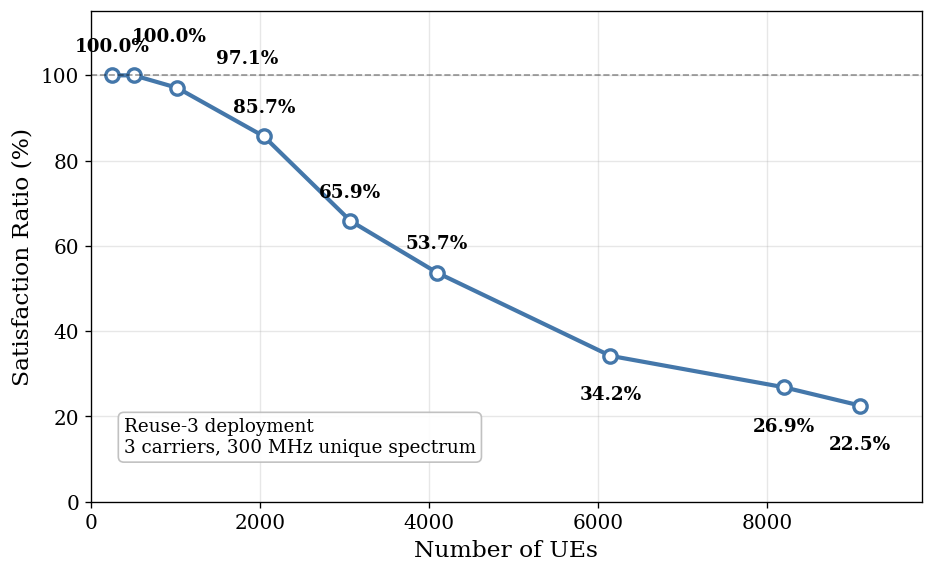

  Saved: satisfaction_vs_load.pdf/png


In [15]:
plot_satisfaction_vs_load(results, output_dir, show=True)

## 4. Inspect Per-UE Data (Observed Peak Load)

Use the maximum `Connected UEs` entry in `input_full.csv` as the peak-load snapshot.


Count active cells from the nearest timestamp in `logs/26.08.2025/cell_power_changes_20250826_212044.csv`, where an active cell is any PCI with transmit power greater than 0 dBm.


Use that active-cell fraction as a coarse occupancy proxy to scale the effective per-RU bandwidth, then show the first 10 per-UE rows together with the active-cell context.

In [16]:
if 'results' in globals() and peak_connected_ues in results:
    peak_df = results[peak_connected_ues].copy()
else:
    peak_df = run_scenario(
        peak_connected_ues,
        seed=42,
        bandwidth_mhz=EFFECTIVE_BW_PER_RU_MHZ,
        activity_factor=ACTIVE_USER_FACTOR,
    ).copy()

peak_df['observed_peak_connected_ues'] = peak_connected_ues
peak_df['observed_active_cells'] = observed_active_cells
peak_df['active_cell_occupancy_pct'] = ACTIVE_CELL_OCCUPANCY_PCT
peak_df['connected_ues_per_active_cell'] = connected_ues_per_active_cell
peak_df['effective_bandwidth_mhz'] = EFFECTIVE_BW_PER_RU_MHZ

print(f"Observed peak time from UE trace: {peak_time_h:.3f} h")
print(f"Connected UEs at peak:           {peak_connected_ues}")
print(f"Nearest power-log snapshot:      {peak_power_time_h:.3f} h")
print(f"Active cells at peak snapshot:   {observed_active_cells}")
print(f"Active-cell occupancy proxy:     {ACTIVE_CELL_OCCUPANCY_PCT:.1f}%")
print(f"Connected UEs per active cell:   {connected_ues_per_active_cell:.1f}")
print(f"Effective BW per RU:             {EFFECTIVE_BW_PER_RU_MHZ:.1f} MHz")
print(f"Modeled satisfaction:            {peak_df['satisfied'].mean() * 100:.1f}%")
print(f"Min throughput:                  {peak_df['throughput_mbps'].min():.1f} Mbps")
print(f"Max demand:                      {peak_df['demand_mbps'].max():.1f} Mbps")
print()
peak_df.head(10)

Observed peak time from UE trace: 20.504 h
Connected UEs at peak:           9096
Nearest power-log snapshot:      20.644 h
Active cells at peak snapshot:   38
Active-cell occupancy proxy:     67.9%
Connected UEs per active cell:   239.4
Effective BW per RU:             67.9 MHz
Modeled satisfaction:            22.5%
Min throughput:                  1.3 Mbps
Max demand:                      25.0 Mbps



,ue_idx,tier,tier_idx,pci,sinr_db,throughput_mbps,demand_mbps,satisfied,n_ues_on_cell,active_ues_on_cell,activity_factor,observed_peak_connected_ues,observed_active_cells,active_cell_occupancy_pct,connected_ues_per_active_cell,effective_bandwidth_mhz
0,0,Lower,0,15,3.03,6.71,19.46,False,212,45,0.24,9096,38,67.86,239.37,67.86
1,1,Lower,0,16,3.17,12.32,11.25,True,117,25,0.24,9096,38,67.86,239.37,67.86
2,2,Lower,0,2,1.36,13.90,21.54,False,69,17,0.24,9096,38,67.86,239.37,67.86
3,3,Lower,0,14,1.86,4.32,17.59,False,215,59,0.24,9096,38,67.86,239.37,67.86
4,4,Lower,0,7,2.72,17.00,2.81,True,67,17,0.24,9096,38,67.86,239.37,67.86
5,5,Lower,0,12,3.15,13.35,24.40,False,91,23,0.24,9096,38,67.86,239.37,67.86
6,6,Lower,0,8,2.67,8.70,19.15,False,137,33,0.24,9096,38,67.86,239.37,67.86
7,7,Lower,0,16,2.63,11.41,19.76,False,117,25,0.24,9096,38,67.86,239.37,67.86
8,8,Lower,0,14,3.43,5.41,3.64,True,215,59,0.24,9096,38,67.86,239.37,67.86
9,9,Lower,0,18,-3.76,1.72,11.53,False,184,56,0.24,9096,38,67.86,239.37,67.86


## 5. Figure: Handover vs. No-Handover Service Continuity

This figure now simulates two comparable UEs with the same 15 Mbps service requirement over the same 2 s session.

UE A remains on its serving cell for the full session, while UE B experiences a 40.5 ms handover interruption at 0.8 s.

The top panel shows the instantaneous delivered rate, and the bottom panel shows the cumulative delivered data gap caused only by the handover event.

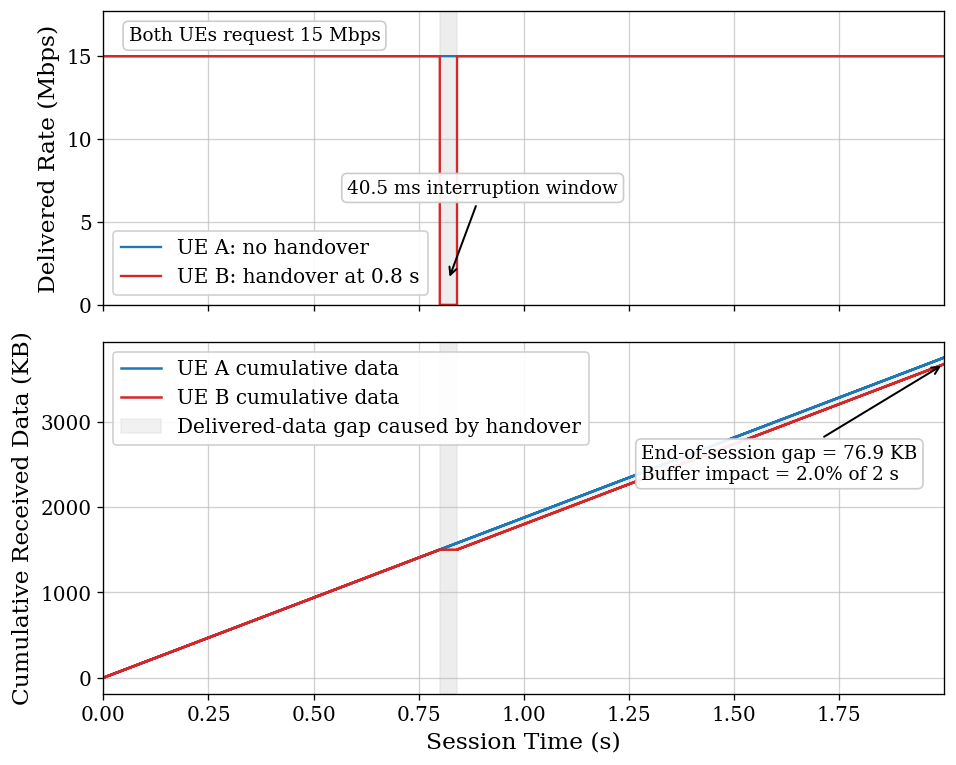

  Saved: handover_continuity.pdf/png


In [2]:
plot_handover_continuity(output_dir, show=True)

## 6. Table: Two-User Handover Impact Summary

This table summarizes the same two-user simulation used in the figure above.

It compares the reference UE without handover against the otherwise comparable UE that experiences the 40.5 ms interruption.

In [3]:
comparison_table = build_handover_comparison_table().copy()

comparison_table = comparison_table.rename(columns={
    'user_case': 'User Case',
    'service_demand_mbps': 'Service Demand (Mbps)',
    'handover_interruption_ms': 'Handover Interruption (ms)',
    'mean_delivered_mbps': 'Mean Delivered Rate (Mbps)',
    'session_data_received_kb': 'Session Data Received (KB)',
    'end_of_session_gap_kb': 'End-of-Session Gap (KB)',
    'buffer_consumed_pct': 'Buffer Consumed (%)',
})

comparison_table

,User Case,Service Demand (Mbps),Handover Interruption (ms),Mean Delivered Rate (Mbps),Session Data Received (KB),End-of-Session Gap (KB),Buffer Consumed (%)
0,Reference UE (no handover),15.00,0.00,15.00,3750.00,0.00,0.00
1,Comparable UE (with handover),15.00,40.50,14.69,3673.12,76.88,2.02


## 7. Conclusion

The notebook is now focused on the handover continuity figure and its companion comparison table, which answer Q4 most directly.

The figure compares two otherwise similar UEs and isolates the service impact of a single 40.5 ms handover interruption relative to a no-handover reference session.

The table condenses that same comparison into a compact summary of delivered rate, received session data, end-of-session gap, and buffer impact.

Together, these results support the paper's QoS claim in the scope studied here: bounded service disruption during handover under the realistic reuse-3 deployment.
